In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
data = pd.read_csv("titanic_large_dataset.csv")

In [2]:
%pip install seaborn

In [6]:
df = pd.DataFrame(data)
print(df)

                  Metric        Value            Description
0           NumberOfRows   20000.0000             Total rows
1        NumberOfColumns     141.0000          Total columns
2  DuplicatePassengerIds       0.0000  Duplicate PassengerId
3     UniquePassengerIds   20000.0000     Unique PassengerId
4          MissingValues  109134.0000          Total missing
5      MissingPercentage       3.8700              Missing %
6         NumericColumns      49.0000           Numeric cols
7     CategoricalColumns      92.0000       Categorical cols
8          SurvivedCount    5485.0000              Survivors
9           SurvivalRate       0.2742          Survival rate


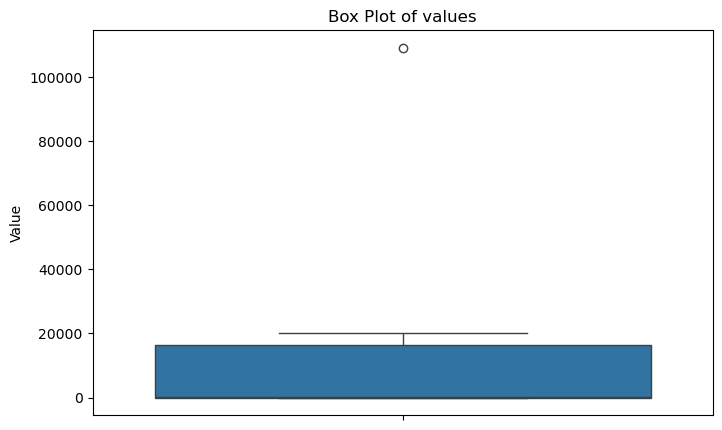

In [8]:
#plotting the Values in the boxplot to identify the outliers
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["Value"])

plt.title("Box Plot of values")
plt.ylabel("Value")
plt.show()

In [11]:
#finding the quantile values to identify where does the values exist more
Q1 = df["Value"].quantile(0.25)
Q3 =  df["Value"].quantile(0.75)
print("Q1 =",Q1)
print("Q3 =",Q3)

Q1 = 15.1525
Q3 = 16371.25


In [12]:
#finding the IQR value between the quantiles
IQR = Q3 - Q1
print("IQR:",IQR)

IQR: 16356.0975


In [13]:
#setting up the two limits till where the outliers must lie
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
print("Lower limit:",lower)
print("Higher limit:",upper)

Lower limit: -24518.993749999998
Higher limit: 40905.39625


In [16]:
#identifying the values which cross the limits
outliers_iqr = df[
(df["Value"] < lower) |
(df["Value"] > upper)
]
print("Outliers detected using IQR:")
print(outliers_iqr)

Outliers detected using IQR:
          Metric     Value    Description
4  MissingValues  109134.0  Total missing


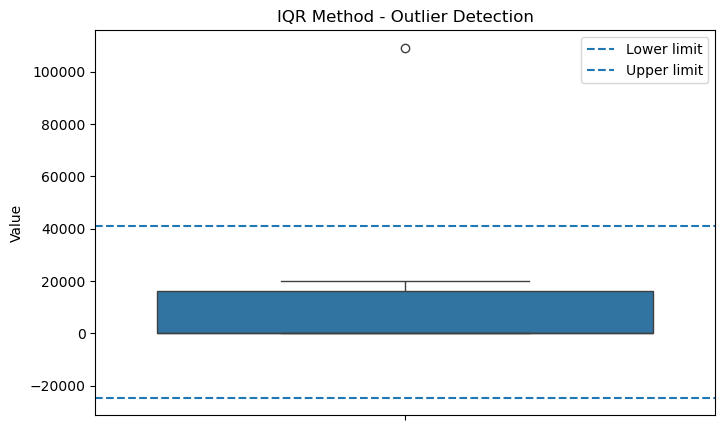

In [17]:
#visualizing the outliers along with the two limits
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["Value"])

plt.axhline(lower, linestyle='--', label='Lower limit')
plt.axhline(upper, linestyle='--', label='Upper limit')

plt.title("IQR Method - Outlier Detection")
plt.legend()

plt.show()

In [19]:
#Treating outliers using Capping method
df["Value_IQR_Capped"] = df["Value"].clip(
lower=lower,
upper=upper
)
print(df[["Value","Value_IQR_Capped"]])

         Value  Value_IQR_Capped
0   20000.0000       20000.00000
1     141.0000         141.00000
2       0.0000           0.00000
3   20000.0000       20000.00000
4  109134.0000       40905.39625
5       3.8700           3.87000
6      49.0000          49.00000
7      92.0000          92.00000
8    5485.0000        5485.00000
9       0.2742           0.27420


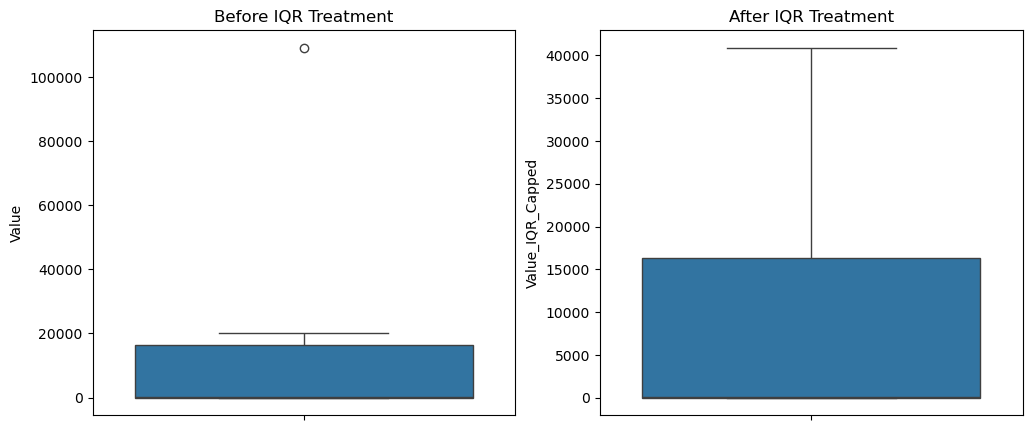

In [21]:
#visuallising the two plots of before and after iqr treatment using capping method
fig,axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Value"], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df["Value_IQR_Capped"], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()

In [22]:
#identifying and treating the outliers using z score method
df["Z_score"] = stats.zscore(df["Value"])

print(df[["Value","Z_score"]])

         Value   Z_score
0   20000.0000  0.140233
1     141.0000 -0.477329
2       0.0000 -0.481714
3   20000.0000  0.140233
4  109134.0000  2.912063
5       3.8700 -0.481593
6      49.0000 -0.480190
7      92.0000 -0.478853
8    5485.0000 -0.311145
9       0.2742 -0.481705


In [23]:
z_outliers = df[abs(df["Z_score"]) > 3]

print("Outliers detected using Z-score")
print(z_outliers)

Outliers detected using Z-score
Empty DataFrame
Columns: [Metric, Value, Description, Value_IQR_Capped, Z_score]
Index: []


In [24]:
df["Z_Outlier"] = abs(df["Z_score"]) > 3

print(df[["Value", "Z_score", "Z_Outlier"]])

         Value   Z_score  Z_Outlier
0   20000.0000  0.140233      False
1     141.0000 -0.477329      False
2       0.0000 -0.481714      False
3   20000.0000  0.140233      False
4  109134.0000  2.912063      False
5       3.8700 -0.481593      False
6      49.0000 -0.480190      False
7      92.0000 -0.478853      False
8    5485.0000 -0.311145      False
9       0.2742 -0.481705      False


In [25]:
#there is no need of capping the outliers as there are values with z scores beyond 3
mean = df["Value"].mean()
std = df["Value"].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

Lower Z-score limit = -86199.13880042259
Upper Z-score limit = 117180.1676404226


In [26]:
df["Value_Z_Capped"] = df["Value"].clip(
lower=lower_z_limit,
upper=upper_z_limit
)

print(df[["Value", "Value_Z_Capped"]])

         Value  Value_Z_Capped
0   20000.0000      20000.0000
1     141.0000        141.0000
2       0.0000          0.0000
3   20000.0000      20000.0000
4  109134.0000     109134.0000
5       3.8700          3.8700
6      49.0000         49.0000
7      92.0000         92.0000
8    5485.0000       5485.0000
9       0.2742          0.2742


         Value  Value_IQR_Capped  Value_Z_Capped
0   20000.0000       20000.00000      20000.0000
1     141.0000         141.00000        141.0000
2       0.0000           0.00000          0.0000
3   20000.0000       20000.00000      20000.0000
4  109134.0000       40905.39625     109134.0000
5       3.8700           3.87000          3.8700
6      49.0000          49.00000         49.0000
7      92.0000          92.00000         92.0000
8    5485.0000        5485.00000       5485.0000
9       0.2742           0.27420          0.2742


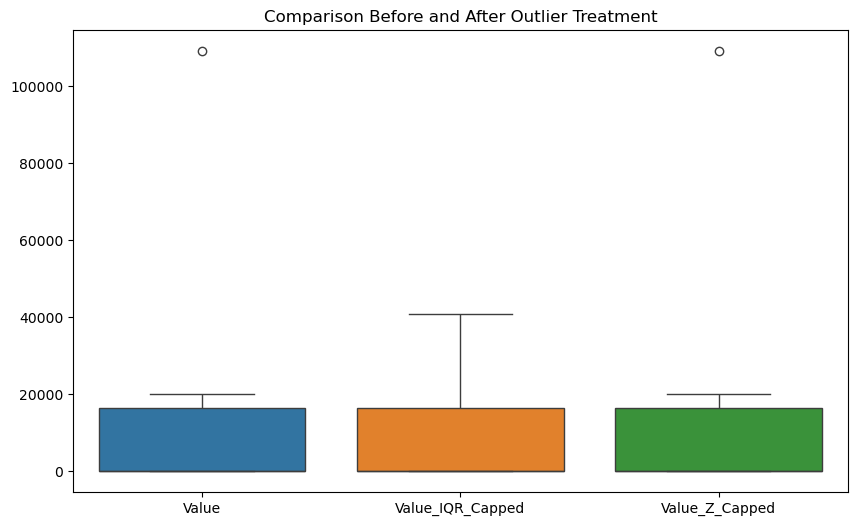

In [27]:
#visualizing all the three methods using boxplot
print(df[["Value",
"Value_IQR_Capped",
"Value_Z_Capped"]])
#You can also visualize them:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
["Value", "Value_IQR_Capped", "Value_Z_Capped"]
])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()